In [1]:
import numpy as np
import matplotlib.pyplot as plt

## predefined helper functions

In [2]:
def generate_random_state(num_cabinets,num_chemicals):
    return np.random.randint(low=0,high=num_cabinets,size=num_chemicals)
    
def evaluate_conflicts(state,dict_constraints,scaler=True):
    con_mat = np.zeros((len(state),len(state)))
    for key,value in dict_constraints.items():
        con_mat[key,list(np.array(value))] = 1
    
    ch_mat = np.zeros((len(state),len(state)))
    for c in range(len(state)):
        occ = np.where(np.array(state)==state[c])[0]
        ch_mat[occ,[c]] = 1
        
        conflicts = con_mat*ch_mat
    if(scaler):    
        return np.sum(conflicts)
    else: 
        return conflicts


def has_conflict(conflicts,action):
    #action (m,n): material m in slot n
    return action[0] in conflicts[action[1]]

## Read constraints

In [3]:
f = open('Dataset.txt', "r")
lines = f.readlines()
f.close()
lines = [l.strip() for l in lines]
data = []
for l in lines:
    temp = [int(l) for l in l.split(',')]
    data.append(temp)

dict_constraints = {}

for d in data:
    dict_constraints[d[0]-1] = [v - 1 for v in d[1:]]

## initial configuration

In [4]:
num_chemicals = 200
num_cabinets = 50
rounds = 500

In [75]:
#sample state
generate_random_state(5,10)
#index: chemical - value: cabinet

array([0, 3, 4, 2, 3, 1, 1, 2, 0, 3], dtype=int32)

In [27]:
random_state = generate_random_state(50,200)
evaluate_conflicts(random_state, dict_constraints)

np.float64(168.0)

## Vanallia (simple) Hill Climbing [5 points]

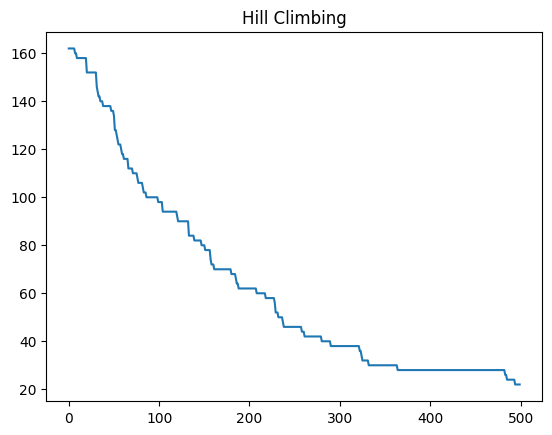

In [ ]:
# your code here...
def hill_climbing(dict_constraints, num_cabinets=20, num_chemicals=200, rounds=500):
    # Start from a random state
    state = generate_random_state(num_cabinets, num_chemicals)

    # Track conflict score over time
    conflicts_log = []

    for i in range(rounds):
        # Evaluate current conflicts
        current_conflicts = evaluate_conflicts(state, dict_constraints)
        conflicts_log.append(current_conflicts)

        # If conflict-free → solution found
        if current_conflicts == 0:
            break

        # Generate ONE neighbor by mutating exactly one chemical
        neighbor = mutate(state.copy(), num_cabinets)
        neighbor_conflicts = evaluate_conflicts(neighbor, dict_constraints)

        # If neighbor improves score, accept it
        if neighbor_conflicts < current_conflicts:
            state = neighbor

    return conflicts_log, state


# Run Hill Climbing
conflicts_log_hc, state_hc = hill_climbing(num_chemicals=num_chemicals,num_cabinets=num_cabinets,dict_constraints=dict_constraints,rounds=rounds)

plt.title("Hill Climbing")
plt.plot(conflicts_log_hc, label="Hill Climbing")
plt.show()

In [69]:
conflicts_log_hc[-1]

np.float64(22.0)

## simulated annealing [10 points]


In [7]:
def mutate(state,num_cabinets):
    num_chemicals = len(state)
    i = np.random.randint(0, num_chemicals )
    state[i] = np.random.randint(0, num_cabinets )
    return state

In [78]:
def run_sa(dict_constraints,tempreture=10000,decay=0.95,num_cabinets=20,rounds=500,num_chemicals=200):
    
    state_c = generate_random_state(num_cabinets,num_chemicals) #stats_c : current state
    conflicts_log = []
    
    for i in range(rounds):
        conflicts_c = evaluate_conflicts( state_c , dict_constraints )
        state_n = mutate(state_c.copy(),num_cabinets) # state_n: candidate next state 
        conflicts_n = evaluate_conflicts(state_n,dict_constraints) # number of conflicts of candidate next state
        delta_e = conflicts_n  -  conflicts_c # next state conflicts - current state conflicts 
        acceptance_probability = np.exp( -delta_e / tempreture ) 
        acceptance_probability = min(acceptance_probability,1) # probabilities cant be bigger than one
        if( acceptance_probability >= np.random.rand() ): # if acceptance probablity is >= a random number between 0 and 1. remember that we want to make it STOCHASTIC. u can use np.random.rand()
            state_c = state_n
            conflicts_log.append(conflicts_n)
            if( conflicts_n == 0 ): # if conflicts_n is zero, we have found an answer
                break
        else:
            conflicts_log.append(conflicts_c)
        
        tempreture *= decay  # decrease temp with decay rate
        
    return conflicts_log,state_c

C:\Users\Vesal\AppData\Local\Temp\ipykernel_15868\1979509942.py:11: RuntimeWarning: overflow encountered in exp
  acceptance_probability = np.exp( -delta_e / tempreture )


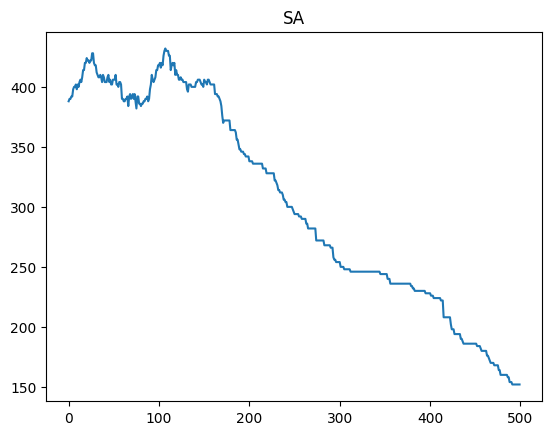

In [79]:
conflicts_log_sa,state_sa = run_sa(num_chemicals=num_chemicals,dict_constraints=dict_constraints,rounds=rounds,num_cabinets=num_cabinets)
plt.title('SA')
plt.plot(conflicts_log_sa,label='SA')
plt.show()

In [80]:
conflicts_log_sa[-1]

np.float64(152.0)

## Genectic Algorithm [20 points]

In [44]:
def cross_over(state1,state2):
    cursor = np.random.randint(0, len(state1)) # generate a random index between 0 and len(state)
    state3 = np.zeros_like(state1)
    # take one side of cursor from each state to make a new state
    if(np.random.rand()<0.5):
        # take first side from state 1 and second side of cursor from state 2
        state3[:cursor] = state1[:cursor]
        state3[cursor:] = state2[cursor:]
    else:
        # take first side from state 2 and second side of cursor from state 1
        state3[:cursor] = state2[:cursor]
        state3[cursor:] = state1[cursor:]
    return state3

In [48]:
# In our implementation of GA chromosome, state and character "c" are all the same. notice that these name can be used interchangably

def run_ga(dict_constraints,cpp=8,num_cabinets=20,rounds=500,num_chemicals=200): #cpp: chromosome per population
    population = []

    for i in range(cpp):
        population.append(generate_random_state( num_cabinets , num_chemicals ))
    
    conflicts_log = []
    for i in range(rounds):
        conflicts = []
        for chromosome in population: # chromosome/state in the population
            conflicts.append(evaluate_conflicts( chromosome , dict_constraints ))
        
        min_conflict = np.min(conflicts)
        conflicts_log.append(min_conflict)
        if( min_conflict == 0 ): # the minimum conflicts is 0 so having 0 conflicts means that we have found an answer
            break
        
        # Assign a selection probability to each chromosome.
        # Store these probabilities in an array called selection_probabilities.
        #
        # Note: Chromosomes with more conflicts should have lower selection probabilities, and vice versa.
        #
        # Caution: If you compute selection_probabilities directly from the number of conflicts,
        # the best chromosomes will dominate the selection process,
        # while the rest will have almost zero chance of being selected. Why is this problematic?
        #
        # Hint: Instead of using raw conflict counts, consider ranking the chromosomes
        # and assigning probabilities based on their ranks (rank-based selection).
        #
        # Optional: You may also include a diversity score between chromosomes to maintain population diversity.
        # Strive for a good balance between fitness and diversity (see the MIT lecture for guidance).
        ranked_indices = np.argsort(conflicts)
        ranks = np.empty_like(ranked_indices)
        ranks[ranked_indices] = np.arange(cpp)
        selection_probabilities = (cpp - ranks) / sum(cpp - ranks)
    
        new_population = []
        for i in range(cpp):
            # choose 2 random samples (chromosomes) from population. better samples should be chosen with higher probabilty
            c1_index,c2_index = np.random.choice(np.arange(cpp),2,True, p=selection_probabilities)
            c3 = cross_over( population[c1_index] , population[c2_index] )
            c3 = mutate( c3 , num_cabinets )
            new_population.append(c3)
        
        population = new_population
        
    return conflicts_log,population[ np.argmin([evaluate_conflicts(ch, dict_constraints) for ch in population]) ] # the chromosome with least conflicts. u can use np.argmin
    # conflicts_log is just a report of how well the algorithms worked in each round.

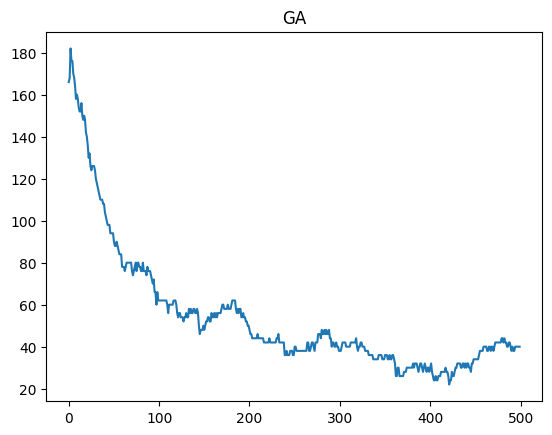

In [50]:
conflicts_log_ga,state_ga = run_ga(num_chemicals=num_chemicals,dict_constraints=dict_constraints,rounds=rounds,num_cabinets=num_cabinets)
plt.title('GA')
plt.plot(conflicts_log_ga,label='GA')
plt.show()

In [82]:
min(conflicts_log_ga)

np.float64(22.0)

## Iterative Minimum Conflict [10 points]

In [51]:
def next_greedy_state(state,num_cabinets,dict_constraints):
    
    conflicts_matrix = evaluate_conflicts(state=state,dict_constraints=dict_constraints,scaler=False)
    conflicts_per_chemical = np.sum(conflicts_matrix,axis=0)
    # conflicts_per_chemical is an array with shape (num_chemicals,1) that shows how many conflicts are caused by each chemical
    # you can print it to check it yourself.
    # choose the chemical that has caused biggest number of conflicts
    max_conflict_chemical = np.argmax( conflicts_per_chemical )
    state[ max_conflict_chemical ] = np.random.randint(0, num_cabinets) # change its cabinet to a random cabinet

    return state
            
def run_imc(dict_constraints,num_cabinets=20,num_chemicals=200,rounds=200):
    conflicts_log = []
    state = generate_random_state(num_cabinets,num_chemicals)
    for i in range( rounds ):
        # find a chemical with biggest number of conflicts and move to a another random cabinet
        state = next_greedy_state(  state  , num_cabinets , dict_constraints )
        conflicts = evaluate_conflicts( state , dict_constraints )
        conflicts_log.append( conflicts )
        if  conflicts == 0 : # conflicts is zero, we have found an answer
            break
    return conflicts_log,state
        

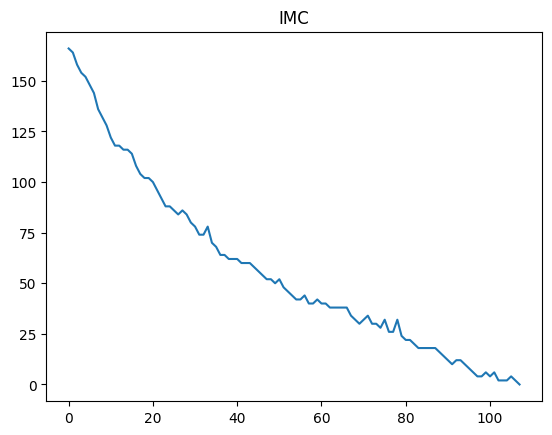

In [52]:
conflicts_log_imc,state_imc = run_imc(num_chemicals=num_chemicals,dict_constraints=dict_constraints,rounds=rounds,num_cabinets=num_cabinets)
plt.title('IMC')
plt.plot(conflicts_log_imc,label='IMC')
plt.show()

In [73]:
conflicts_log_imc[-1]

np.float64(0.0)

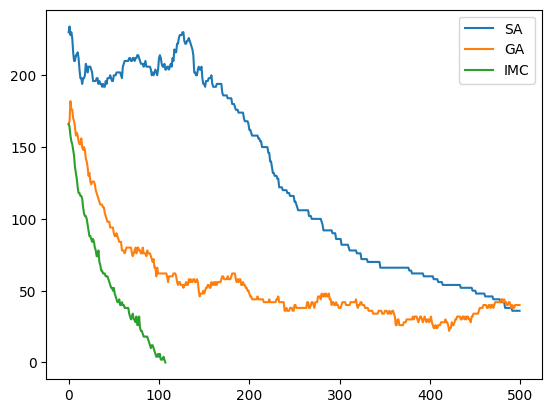

In [53]:
plt.plot(conflicts_log_sa,label='SA')
plt.plot(conflicts_log_ga,label='GA')
plt.plot(conflicts_log_imc,label='IMC')
plt.legend()
plt.show()

## Backtracking [10 points]

In [54]:
class Stack:
    "A cabinet with a last-in-first-out (LIFO) queuing policy."
    def __init__(self):
        self.list = []

    def push(self,item):
        "Push 'item' onto the stack"
        self.list.append(item)

    def pop(self):
        "Pop the most recently pushed item from the stack"
        return self.list.pop()

    def is_empty(self):
        "Returns true if the stack is empty"
        return len(self.list) == 0


class CSP_problem:
    def __init__(self,num_cabinets,num_chemicals,dict_constraints):
        self.num_cabinets = num_cabinets
        self.num_chemicals = num_chemicals
        self.dict_constraints = dict_constraints
        
    def get_successors(self,state):
        successors = []
        actions = np.arange(self.num_cabinets)
        unassigned_chemical_index = np.where(state==-1)[0][0]
        
        for action in actions:
            cost = 0
            next_state = state.copy()
            next_state[ unassigned_chemical_index ] =  action 
            if(np.sum(next_state==action)==1): # used an empty cabinet
                cost = 1
                
            # evaluate number of conflicts on this specific cabinet
            conflicts = self.evaluate_conflicts(next_state,unassigned_chemical_index,self.dict_constraints) 
            if( conflicts == 0 ):
                successors.append(( next_state , action , cost ))

        return successors
    
    
    def evaluate_conflicts(self,state,index,dict_constraints):
        conflicts = 0
        shared_set = set(np.where(state==state[index])[0])
        constraint_set = set(dict_constraints[index])
        conflicts += len(shared_set.intersection(constraint_set))

        return conflicts
            
            
    
#    def is_goal_state(self,state):
    def get_start_state(self):
        # start state is array: [-1,-1,-1 ..., -1] with shape(num_chemicals)
        # This means all of the chemicals are assigned to cabinet with index -1
        # which means we have not put them in any cabinet yet
        state = -np.ones(self.num_chemicals)
        return state
    
    def is_goal_state(self,state):
        return np.sum(state==-1)==0

def generic_search(problem, fringe, add_to_fringe_fn):
    start = (problem.get_start_state(), 0)  # (node, cost)
    add_to_fringe_fn(fringe, start, 0)
    visited_nodes_count = 0
    while not fringe.is_empty():
        (node,cost) = fringe.pop()
        visited_nodes_count +=1
        
        if problem.is_goal_state(node):
            return node,visited_nodes_count

        for child_node, child_action, child_cost in problem.get_successors(node):
            new_cost = cost + child_cost
            new_state = (child_node, new_cost)
            add_to_fringe_fn(fringe, new_state, new_cost)

            
def dfs(problem):
    fringe = Stack()
    def add_to_fringe_fn(fringe, state, cost):
        fringe.push(state)

    return generic_search(problem, fringe, add_to_fringe_fn)

def run_dfs(num_chemicals,num_cabinets,dict_constraints):
    problem = CSP_problem(num_cabinets,num_chemicals,dict_constraints)
    solution,visited_nodes_count = dfs(problem)
    return solution,visited_nodes_count

## Beam Search [15 points]

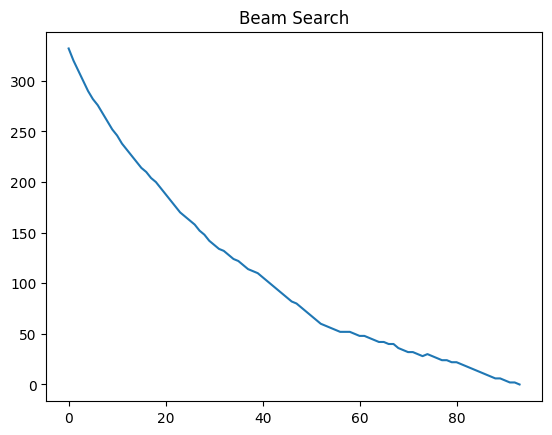

In [59]:
# your code here... think of a good heuristic
def beam_search(dict_constraints, num_cabinets=20, num_chemicals=200,
                beam_width=10, successors_per_state=5, rounds=500):

    # Initialize beam
    beam = [generate_random_state(num_cabinets, num_chemicals) for _ in range(beam_width)]
    conflicts_log = []

    def heuristic(state):
        c = evaluate_conflicts(state, dict_constraints)
        loads = np.bincount(state, minlength=num_cabinets)
        load_pen = np.sum(loads**2)
        return c + 0.01 * load_pen

    for _ in range(rounds):

        # Evaluate beam
        scores = [heuristic(s) for s in beam]
        best_conflict = min([evaluate_conflicts(s, dict_constraints) for s in beam])
        conflicts_log.append(best_conflict)
        if best_conflict == 0:
            break

        successors = []

        # Expand each parent
        for parent in beam:
            # IMC-style successor expansion
            conflicts_matrix = evaluate_conflicts(parent, dict_constraints, scaler=False)
            conflicts_per_chemical = np.sum(conflicts_matrix, axis=0)
            worst_chem = np.argmax(conflicts_per_chemical)

            for _ in range(successors_per_state):
                new = parent.copy()
                new[worst_chem] = np.random.randint(0, num_cabinets)
                successors.append(new)

        # Select top beam_width states
        scores = [heuristic(s) for s in successors]
        idx = np.argsort(scores)[:beam_width]
        beam = [successors[i] for i in idx]

    # Return best state
    final_scores = [evaluate_conflicts(s, dict_constraints) for s in beam]
    return conflicts_log, beam[np.argmin(final_scores)]

# Run Beam Search
conflicts_log_bs, state_bs = beam_search(dict_constraints=dict_constraints,num_cabinets=num_cabinets,num_chemicals=num_chemicals,beam_width=10)

# Plot the conflict log
plt.title('Beam Search')
plt.plot(conflicts_log_bs, label='Beam Search')
plt.show()

In [74]:
conflicts_log_bs[-1]

np.float64(0.0)

Write a code to estimate ratio of feasible state space size to the world state space size.

In [66]:
# your code here...
def estimate_feasible_ratio(
    dict_constraints, num_cabinets=20, num_chemicals=200, samples=5000):
    feasible_count = 0

    for _ in range(samples):
        state = generate_random_state(num_cabinets, num_chemicals)

        # YOUR FEASIBILITY CHECK:
        # A state is feasible if it has 0 conflicts
        conflicts = evaluate_conflicts(state, dict_constraints)

        if conflicts == 0:
            feasible_count += 1

    return feasible_count / samples

In [68]:
result = estimate_feasible_ratio(dict_constraints)
print(result)


0.0


In [57]:
num_cabinets = 25

solution,visited_nodes_count = run_dfs(num_chemicals=num_chemicals,num_cabinets=num_cabinets,dict_constraints=dict_constraints)
conflicts = evaluate_conflicts(solution,dict_constraints)
if(conflicts == 0):

    print(f"There is a solution for putting {num_chemicals} chemicals in {num_cabinets} cabinets, while keeping the constraints satisfied")
else:
    print(f"there is NO solution for puting {num_chemicals} chemicals in {num_cabinets} cabinets,  while keeping the constraints satisfied")         

There is a solution for putting 200 chemicals in 25 cabinets, while keeping the constraints satisfied


# Theoretical Questions

---

### a) For the backtracking algorithm, unlike the previous algorithms, we do not have a conflict count versus round (iteration) graph. Why is that?  
Guidance: In local search algorithms (A to D), we start with a random state in which all chemicals are placed in compartments, and at each step, we try to reduce the number of conflicts. In the backtracking algorithm, implemented as Depth-First Search (DFS) in this assignment, we start from an empty state and assign chemicals to compartments sequentially. If there is one or more conflicts in a state, we do not expand that state.

Backtracking (DFS) fundamentally behaves differently from the local-search algorithms.

In **local search algorithms** (Hill Climbing, SA, GA, IMC):

* We **start with a complete assignment**: every chemical already sits in some cabinet.
* Each iteration **modifies the existing full assignment**, and we can measure the **number of conflicts at each step**.
* Therefore we can plot a conflict-count vs. iteration graph.

In **Backtracking (DFS)** in this assignment:

* We **start from an empty state** (all entries = –1), meaning no chemicals are assigned yet.
* Chemicals are assigned **one at a time** in sequence.
* A state that has **any conflict is immediately discarded** and never expanded.
* Therefore:

  * We never have a *running conflict count*.
  * DFS does not try to *minimize* conflicts; it tries to **avoid any conflict entirely**.
  * Intermediate states are only partially filled, and evaluating conflict counts makes no sense when many chemicals are unassigned.

Thus, DFS is a **search in a constrained space**, not an optimization over a full assignment, so plotting “conflicts per iteration” is not meaningful.

#### b) If we want to be absolutely certain about the minimum number of compartments that satisfy the problem constraints, which algorithms can we use? Why?

Only **complete** search algorithms can guarantee the optimal minimum number of compartments:

### **Algorithms that CAN guarantee the optimal minimum:**

1. **Backtracking (DFS/Full CSP Search)**

### **Why?**

* These algorithms **systematically explore** the state space.
* They never skip possible assignments.
* They can be run repeatedly with k = 1,2,3,… compartments until a feasible solution appears.
* This first feasible solution is **provably optimal** because all smaller k values were exhausted.

### **Algorithms that CANNOT guarantee optimality:**

* Hill Climbing
* Simulated Annealing
* Genetic Algorithm
* Iterative Min-Conflicts
* Beam Search

These are **local-search / heuristic / incomplete** algorithms.
They explore only a tiny fraction of the state space and may miss valid solutions entirely.

### c) Given 200 chemicals and 50 compartments, calculate the size of the world state.

Each of the 200 chemicals can independently be assigned to any of the 50 cabinets.

$
\text{World State Size} = 50^{200}
$

Let’s express its magnitude:

$
\log_{10}(50^{200}) = 200 \log_{10}(50) \approx 200 \cdot 1.69897 \approx 339.794
$

So:

$
50^{200} \approx 10^{339.8}
$

This number is astronomically large — far beyond feasible brute-force enumeration.

### d) Based on your understanding of the problem and observing the success rates of the algorithms in the previous section, analyze the reasons for the success or failure of these algorithms.

### **1. Hill Climbing (Vanilla)**

* Often gets stuck in **local minima**, where no single-step improvement is possible.
* Cannot escape plateaus or ridges.
* Works only when the landscape is smooth and unimodal (not true here).

**Result:** frequently fails.

---

### **2. Simulated Annealing**

* Allows **occasional uphill moves**, helping escape local minima.
* Performance depends on:

  * cooling schedule
  * initial temperature
  * mutation step size

**Result:** usually succeeds but can fail if temperature decays too fast or the search space is rugged.

---

### **3. Genetic Algorithm**

* Maintains a **population**, not a single state.
* Uses crossover + mutation to explore diverse areas of the search space.
* Rank-based selection prevents the population from collapsing.
* Very good for large combinatorial spaces.

**Result:** high success rate; typically one of the best among stochastic algorithms.

---

### **4. Iterative Min-Conflicts (IMC)**

* Highly effective when:

  * Many conflicts are local
  * A small number of variables cause most violations
* It directly targets the **chemical causing the most conflicts**.
* Works particularly well in large, sparse constraint graphs.

**Result:** often succeeds very quickly; one of the best algorithms for CSPs like graph coloring.

---

### **5. Beam Search**

* Explores several partial assignments at once.
* Not complete — may discard the path leading to the solution if beam width is too small.
* Good with a strong heuristic; risky otherwise.

**Result:** success depends heavily on beam width and heuristic quality.

---

### **6. Backtracking (DFS)**

* **Complete** — guaranteed to find a solution.
* But exponential runtime in worst case.
* Efficient only when:

  * constraints prune many branches
  * variable ordering is good (MRV, LCV etc.)

**Result:** guaranteed success; may be slow on large instances but works well when constraints are strong.